# 🏋️ Predicting a Powerlifter's Total from Who They Are

**Question:** *Before a lifter ever touches a barbell at a meet, how well can we predict their total (squat + bench + deadlift) using only bodyweight, sex, age, equipment, and meet context?*

**Dataset:** OpenPowerlifting (386k entries, 8.5k meets, 1974-2018).

**Plan**
1. Load and clean the data (this dataset has traps: bench-only meets, DQs, missing ages)
2. Explore what drives totals
3. Build features and split **by lifter** to avoid leakage
4. Compare baseline, linear, and gradient-boosted models
5. Interpret the best model and check where it fails

In [16]:
!unzip -o -q archive.zip

In [17]:
import glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import lightgbm as lgb
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
RNG = 42

def find(name):
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) + glob.glob(f'**/{name}', recursive=True)
    return hits[0]

df = pd.read_csv(find('openpowerlifting.csv'))
meets = pd.read_csv(find('meets.csv'))
print(df.shape, meets.shape)
df.head()

(386414, 17) (8482, 8)


,MeetID,Name,Sex,Equipment,Age,Division,BodyweightKg,WeightClassKg,Squat4Kg,BestSquatKg,Bench4Kg,BestBenchKg,Deadlift4Kg,BestDeadliftKg,TotalKg,Place,Wilks
0,0,Angie Belk Terry,F,Wraps,47.0,Mst 45-49,59.60,60,NaN,47.63,NaN,20.41,NaN,70.31,138.35,1,155.05
1,0,Dawn Bogart,F,Single-ply,42.0,Mst 40-44,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
2,0,Dawn Bogart,F,Single-ply,42.0,Open Senior,58.51,60,NaN,142.88,NaN,95.25,NaN,163.29,401.42,1,456.38
3,0,Dawn Bogart,F,Raw,42.0,Open Senior,58.51,60,NaN,NaN,NaN,95.25,NaN,NaN,95.25,1,108.29
4,0,Destiny Dula,F,Raw,18.0,Teen 18-19,63.68,67.5,NaN,NaN,NaN,31.75,NaN,90.72,122.47,1,130.47


## 1. Data cleaning

Quick look at what is missing. The `*4Kg` fourth-attempt columns are almost entirely empty, and **Age is missing for ~62% of rows**, so we cannot simply drop those rows.

In [18]:
(df.isna().mean().sort_values(ascending=False).head(8)*100).round(1).rename('% missing').to_frame()

,% missing
Squat4Kg,99.7
Bench4Kg,99.5
Deadlift4Kg,99.3
Age,61.9
BestSquatKg,22.9
BestDeadliftKg,17.7
BestBenchKg,7.8
Wilks,6.3


### Trap 1: not every meet is full-power
Some rows are bench-only or deadlift-only events. There, `TotalKg` is just one lift, which would badly pollute a "total" model. A full-power total should equal squat + bench + deadlift, so I keep only rows where all three lifts are positive.

In [19]:
d = df.merge(meets[['MeetID','Federation','Date','MeetCountry']], on='MeetID', how='left')
n0 = len(d)

d = d.dropna(subset=['TotalKg','BodyweightKg','BestSquatKg','BestBenchKg','BestDeadliftKg'])
print(f'after dropping missing totals / lifts (DQ, partial events): {len(d):,}  (-{n0-len(d):,})')

d = d[(d.BestSquatKg>0)&(d.BestBenchKg>0)&(d.BestDeadliftKg>0)&(d.TotalKg>0)]
d['sum3'] = d.BestSquatKg + d.BestBenchKg + d.BestDeadliftKg
d = d[(d.TotalKg - d.sum3).abs() < 1.0]      # total must equal the three lifts
print(f'after requiring total == squat+bench+deadlift: {len(d):,}')

d = d[d.BodyweightKg.between(30, 250) & (d.Equipment != 'Straps')]
d['Date'] = pd.to_datetime(d.Date)
d['Year'] = d.Date.dt.year
d = d.reset_index(drop=True)
print(f'final modelling set: {len(d):,} entries, {d.Name.nunique():,} lifters, {d.MeetID.nunique():,} meets')

after dropping missing totals / lifts (DQ, partial events): 285,600  (-100,814)
after requiring total == squat+bench+deadlift: 285,598
final modelling set: 285,546 entries, 112,712 lifters, 7,342 meets


## 2. Exploration

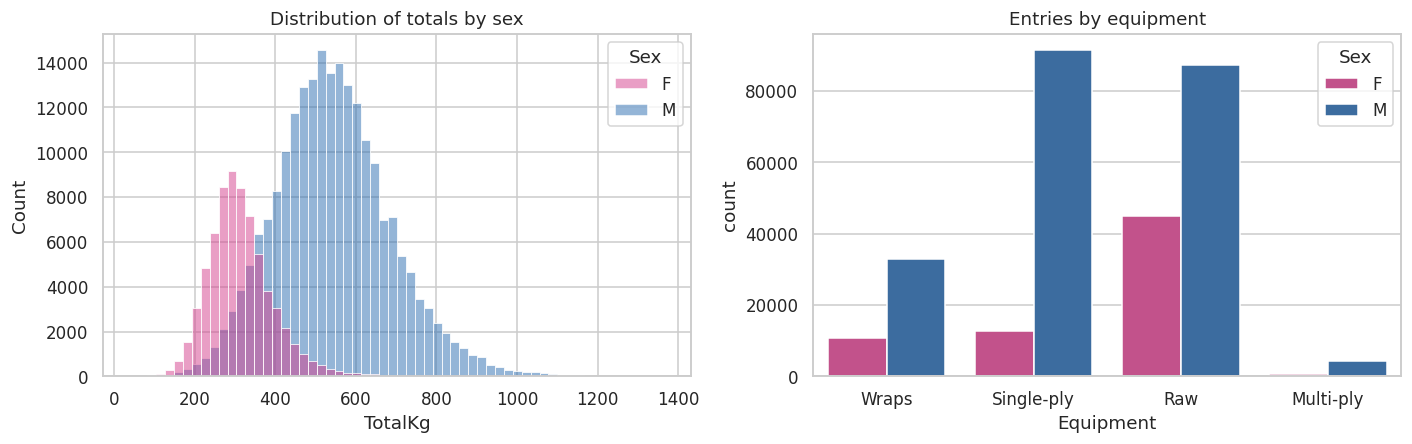

                count   mean  median
Sex Equipment                       
F   Multi-ply     730  470.0   474.0
    Raw         45059  299.0   295.0
    Single-ply  12734  345.0   335.0
    Wraps       10857  324.0   315.0
M   Multi-ply    4370  799.0   798.0
    Raw         87316  541.0   540.0
    Single-ply  91502  511.0   498.0
    Wraps       32978  606.0   602.0


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(data=d, x='TotalKg', hue='Sex', bins=60, ax=ax[0], palette={'M':'#2b6cb0','F':'#d53f8c'})
ax[0].set_title('Distribution of totals by sex')
sns.countplot(data=d, x='Equipment', hue='Sex', ax=ax[1], palette={'M':'#2b6cb0','F':'#d53f8c'})
ax[1].set_title('Entries by equipment'); plt.tight_layout(); plt.show()
print(d.groupby(['Sex','Equipment']).TotalKg.agg(['count','mean','median']).round(0))

**Equipment matters a lot:** multi-ply and wraps lifters post much bigger totals than raw lifters (about +260 kg for multi-ply men). Single-ply is the surprise: its mean total for men is *lower* than raw, because it is dominated by older and lighter-weight federation lifters. So the effect is entangled with who competes in each equipment class, which is why the model also needs age, year and federation.

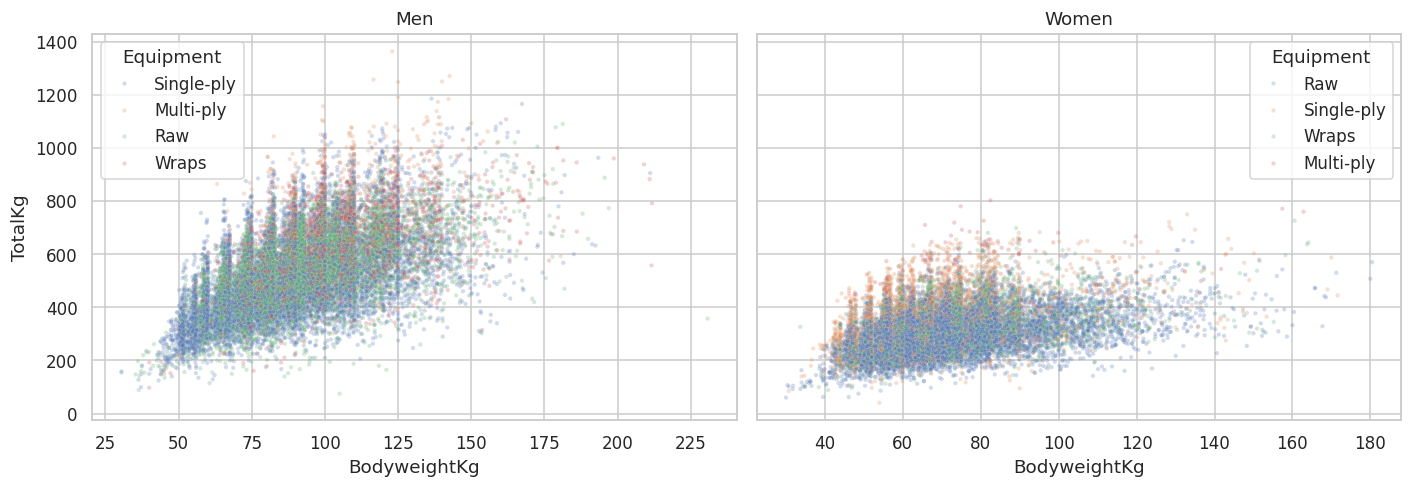

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for a, sx in zip(ax, ['M','F']):
    s = d[(d.Sex==sx)].sample(min(25000, (d.Sex==sx).sum()), random_state=RNG)
    sns.scatterplot(data=s, x='BodyweightKg', y='TotalKg', hue='Equipment', alpha=.25, s=8, ax=a, rasterized=True)
    a.set_title('Men' if sx=='M' else 'Women')
plt.tight_layout(); plt.show()

Totals rise with bodyweight, with a wide spread at every weight (that spread is the part we cannot explain from these features, since it reflects training level).

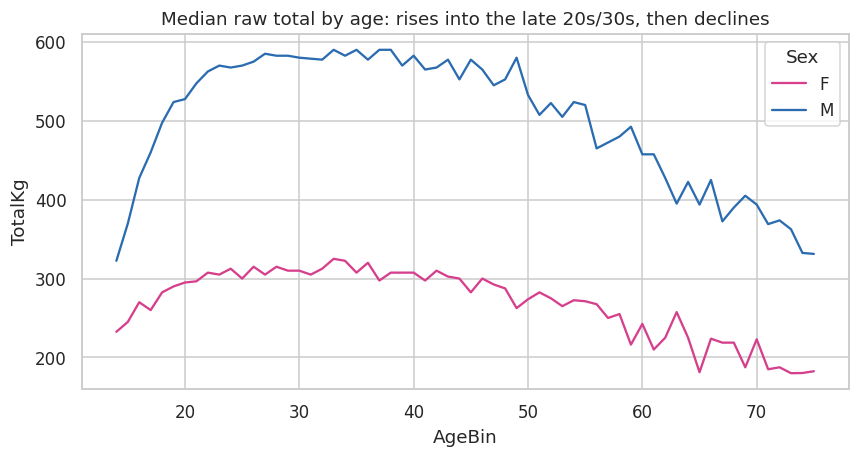

Age known for 37% of the modelling set


In [22]:
a = d.dropna(subset=['Age']).copy()
a = a[a.Age.between(14, 80)]
a['AgeBin'] = a.Age.round().astype(int)
g = a[a.Equipment=='Raw'].groupby(['Sex','AgeBin']).TotalKg.median().reset_index()
g = g[g.AgeBin.isin(range(14, 76))]
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.lineplot(data=g, x='AgeBin', y='TotalKg', hue='Sex', palette={'M':'#2b6cb0','F':'#d53f8c'}, ax=ax)
ax.set_title('Median raw total by age: rises into the late 20s/30s, then declines'); plt.show()
print('Age known for', f'{d.Age.notna().mean():.0%}', 'of the modelling set')

## 3. Features and a leakage-safe split
**Important:** the same lifter appears in many meets. A random row split would let the model "recognise" a lifter in test from their training rows, which inflates scores. I therefore split **by lifter name** with `GroupShuffleSplit`.

I also add:
- `AgeMissing` flag, because whether age was recorded may itself carry signal (e.g. federation habits)
- `Year` to capture how the sport changed over time
- `Federation` and `MeetCountry` as meet context

I deliberately **exclude** squat, bench, deadlift and Wilks, since they are the answer (or computed from it).

In [23]:
d['AgeMissing'] = d.Age.isna().astype(int)
d['SexM'] = (d.Sex=='M').astype(int)
for c in ['Equipment','Federation','MeetCountry']:
    d[c] = d[c].astype('category')

NUM = ['BodyweightKg','Age','AgeMissing','SexM','Year']
CAT = ['Equipment','Federation','MeetCountry']
FEATS = NUM + CAT
X, y, groups = d[FEATS], d.TotalKg, d.Name

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RNG)
tr, te = next(gss.split(X, y, groups))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
print(f'train {len(tr):,} | test {len(te):,} | lifter overlap: {len(set(groups.iloc[tr]) & set(groups.iloc[te]))}')

train 228,322 | test 57,224 | lifter overlap: 0


## 4. Models

In [24]:
def report(name, pred):
    return dict(model=name, MAE=mean_absolute_error(yte, pred),
                RMSE=mean_squared_error(yte, pred)**.5, R2=r2_score(yte, pred))
results, preds = [], {}

# Baseline 1: group means by sex x equipment
gm = pd.concat([Xtr[['SexM','Equipment']], ytr], axis=1).groupby(['SexM','Equipment'], observed=True).TotalKg.mean()
p = Xte.set_index(['SexM','Equipment']).index.map(gm).to_numpy(dtype=float)
preds['Sex x Equipment mean'] = p; results.append(report('Baseline: sex x equipment mean', p))

# Baseline 2: Ridge on one-hot + bodyweight interactions
def lin_frame(X):
    Z = pd.DataFrame({'bw': X.BodyweightKg, 'bw2': X.BodyweightKg**2, 'SexM': X.SexM,
                      'bwxSex': X.BodyweightKg*X.SexM,
                      'age': X.Age.fillna(30), 'AgeMissing': X.AgeMissing,
                      'age2': X.Age.fillna(30)**2/100, 'Year': X.Year})
    return pd.concat([Z, pd.get_dummies(X.Equipment, dtype=float)], axis=1)
Ltr, Lte = lin_frame(Xtr), lin_frame(Xte)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Ltr, ytr)
preds['Ridge'] = ridge.predict(Lte); results.append(report('Ridge (hand-built features)', preds['Ridge']))

# LightGBM (handles NaN age + categoricals natively)
params = dict(objective='regression', n_estimators=2000, learning_rate=0.05, num_leaves=63,
              min_child_samples=40, subsample=.8, subsample_freq=1, colsample_bytree=.8,
              random_state=RNG, verbose=-1)
# validation slice (grouped) from train for early stopping
gs2 = GroupShuffleSplit(n_splits=1, test_size=.15, random_state=RNG)
a_idx, v_idx = next(gs2.split(Xtr, ytr, groups.iloc[tr]))
m = lgb.LGBMRegressor(**params)
m.fit(Xtr.iloc[a_idx], ytr.iloc[a_idx], eval_set=[(Xtr.iloc[v_idx], ytr.iloc[v_idx])],
      callbacks=[lgb.early_stopping(100, verbose=False)])
print('best iteration:', m.best_iteration_)
preds['LightGBM'] = m.predict(Xte); results.append(report('LightGBM', preds['LightGBM']))

res = pd.DataFrame(results).set_index('model').round(3)
res

best iteration: 386


,MAE,RMSE,R2
model,,,
Baseline: sex x equipment mean,94.876,124.104,0.432
Ridge (hand-built features),75.657,98.734,0.640
LightGBM,64.807,84.965,0.734


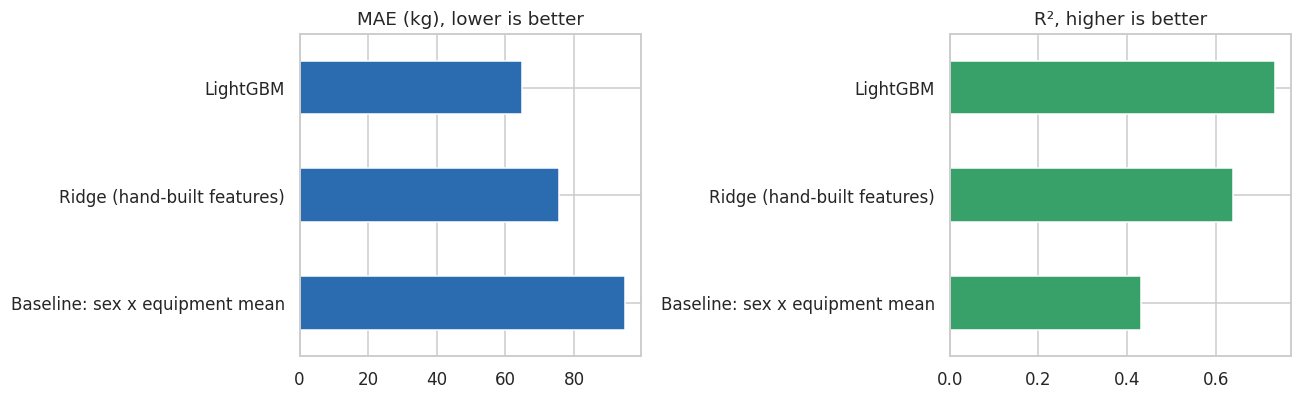

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
res.MAE.plot.barh(ax=ax[0], color='#2b6cb0'); ax[0].set_title('MAE (kg), lower is better'); ax[0].set_ylabel('')
res.R2.plot.barh(ax=ax[1], color='#38a169'); ax[1].set_title('R², higher is better'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

## 5. Interpreting the best model

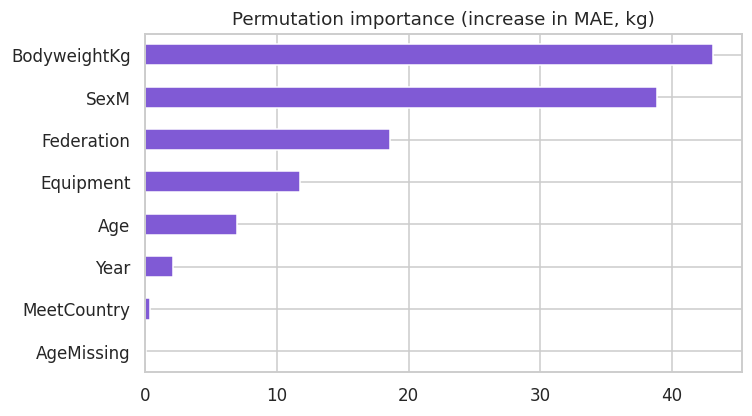

In [26]:
pi = permutation_importance(m, Xte.sample(30000, random_state=RNG), yte.loc[Xte.sample(30000, random_state=RNG).index],
                            n_repeats=5, random_state=RNG, scoring='neg_mean_absolute_error')
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
imp.plot.barh(figsize=(7,4), color='#805ad5'); plt.title('Permutation importance (increase in MAE, kg)'); plt.show()

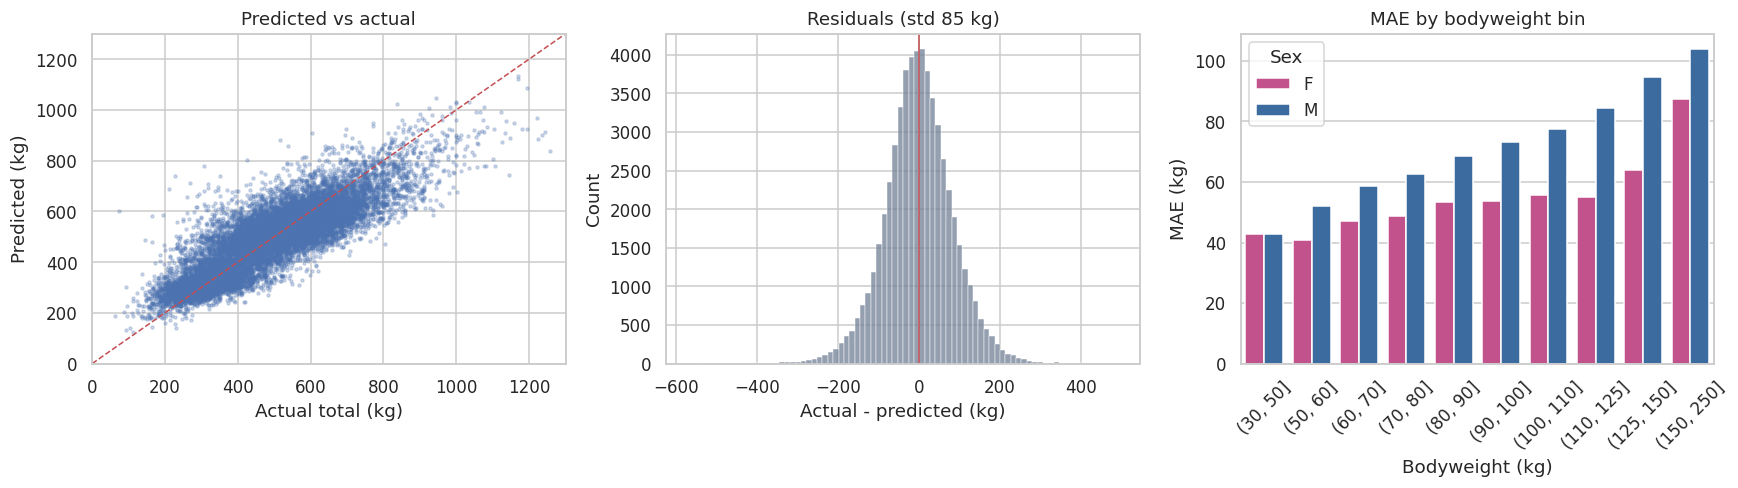

In [27]:
best = preds['LightGBM']
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

s = np.random.RandomState(RNG).choice(len(yte), 15000, replace=False)
ax[0].scatter(yte.iloc[s], best[s], s=4, alpha=.25)
lim = [0, 1300]; ax[0].plot(lim, lim, 'r--', lw=1)
ax[0].set(xlabel='Actual total (kg)', ylabel='Predicted (kg)', title='Predicted vs actual', xlim=lim, ylim=lim)

resid = yte.values - best
sns.histplot(resid, bins=80, ax=ax[1], color='#718096'); ax[1].axvline(0, color='r', lw=1)
ax[1].set_title(f'Residuals (std {resid.std():.0f} kg)'); ax[1].set_xlabel('Actual - predicted (kg)')

t = Xte.assign(abs_err=np.abs(resid), Sex=np.where(Xte.SexM==1,'M','F'))
t['bw_bin'] = pd.cut(t.BodyweightKg, [30,50,60,70,80,90,100,110,125,150,250])
sns.barplot(data=t, x='bw_bin', y='abs_err', hue='Sex', palette={'M':'#2b6cb0','F':'#d53f8c'}, ax=ax[2], errorbar=None)
ax[2].set(title='MAE by bodyweight bin', xlabel='Bodyweight (kg)', ylabel='MAE (kg)'); ax[2].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### Does the model learn sensible physiology?
Predicted totals for a hypothetical raw lifter, with the competition year held fixed, across bodyweights and ages.

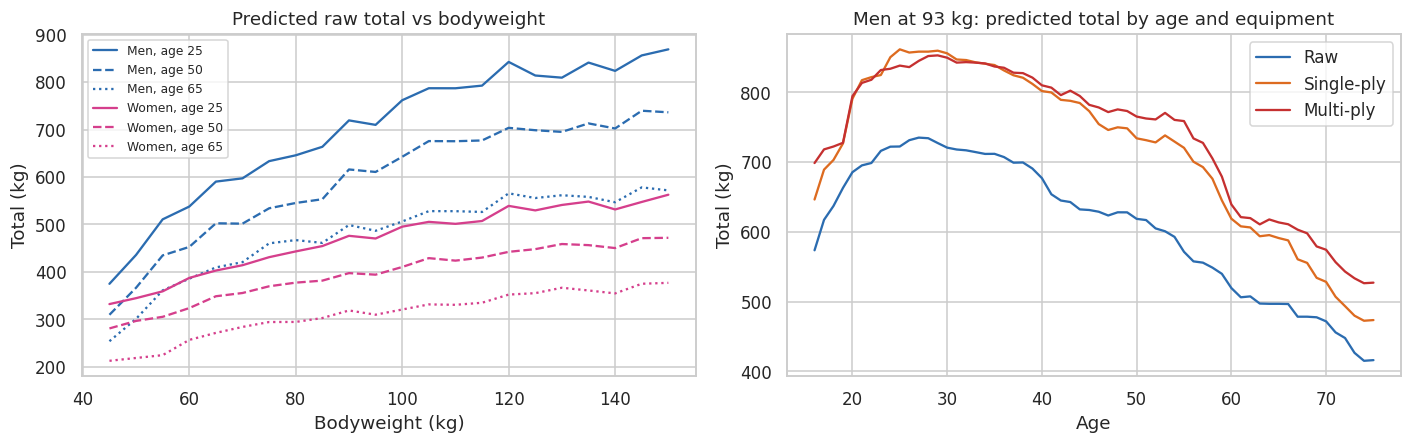

In [28]:
def sim(sex, equip, bws, age, fed='IPF', country='USA', year=2017):
    return pd.DataFrame({'BodyweightKg': bws, 'Age': age, 'AgeMissing': 0, 'SexM': int(sex=='M'), 'Year': year,
                         'Equipment': pd.Categorical([equip]*len(bws), categories=d.Equipment.cat.categories),
                         'Federation': pd.Categorical([fed]*len(bws), categories=d.Federation.cat.categories),
                         'MeetCountry': pd.Categorical([country]*len(bws), categories=d.MeetCountry.cat.categories)})[FEATS]
bws = np.arange(45, 151, 5)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for sx, col in [('M','#2b6cb0'),('F','#d53f8c')]:
    for age, ls in [(25,'-'),(50,'--'),(65,':')]:
        ax[0].plot(bws, m.predict(sim(sx,'Raw',bws,age)), ls, color=col, label=f"{'Men' if sx=='M' else 'Women'}, age {age}")
ax[0].set(title='Predicted raw total vs bodyweight', xlabel='Bodyweight (kg)', ylabel='Total (kg)'); ax[0].legend(fontsize=8)
ages = np.arange(16, 76)
for eq, col in [('Raw','#2b6cb0'),('Single-ply','#dd6b20'),('Multi-ply','#c53030')]:
    ax[1].plot(ages, [m.predict(sim('M',eq,[93],a))[0] for a in ages], color=col, label=eq)
ax[1].set(title='Men at 93 kg: predicted total by age and equipment', xlabel='Age', ylabel='Total (kg)'); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Conclusions

In [29]:
r = res.loc['LightGBM']; b = res.loc['Baseline: sex x equipment mean']
print(f"Baseline MAE {b.MAE:.0f} kg  ->  LightGBM MAE {r.MAE:.0f} kg  ({(1-r.MAE/b.MAE):.0%} lower)")
print(f"LightGBM explains {r.R2:.0%} of the variance in totals on completely unseen lifters.")

Baseline MAE 95 kg  ->  LightGBM MAE 65 kg  (32% lower)
LightGBM explains 73% of the variance in totals on completely unseen lifters.


**Takeaways**
- Sex, equipment and bodyweight explain most of what can be explained about a total. Age adds a clear inverted-U curve (raw lifters plateau from the early 20s to about 40, then decline).
- Gradient boosting beats the baselines because the bodyweight-to-total relationship is non-linear and interacts with sex and equipment.
- Typical error is still about 65 kg (MAE). The leftover spread is largely **training level**, which is not in this data. Anything much better needs lift history, i.e. the lifter's **previous meet results**.
- Cleaning mattered: bench-only meets and DQs would otherwise have corrupted the target.

**Limitations and next steps**
- Age is missing for most rows, so the age effect is learned from a subset.
- Same-lifter splitting is stricter than random splitting. Scores here are what to expect for a *new* lifter.
- Natural extension: predict **next-meet total** using the lifter's previous totals (a progression model). That is where much higher accuracy would come from.
- Try quantile regression for prediction intervals (for example "80% of lifters like this total between X and Y").